# Cap. 2: Statistical Learning aplicado a WDO e WIN

**Objetivo:** levar os conceitos das aulas 2.1 a 2.4 para os dados reais, usando só as ferramentas do capítulo (KNN e regressão linear).

| Aula | Pergunta aqui |
|---|---|
| 2.1 Modelos de regressão | Quanto do retorno do próximo minuto é **redutível**? A resposta muda se o alvo é a *direção* ou a *intensidade* do movimento? Reta, parábola ou vizinhos? |
| 2.2 Dimensionalidade e modelos estruturados | Quão longe ficam os "vizinhos" quando aumenta o número de features? O que acontece com o KNN quando entram features inúteis? |
| 2.3 Seleção de modelos e viés-variância | Como o erro de treino e o de teste mudam com a **flexibilidade** do modelo? Quanto do erro é viés e quanto é variância? Quando um modelo flexível valeria a pena? |
| 2.4 Classificação | Um classificador KNN bate o chute ingênuo? As probabilidades dele são confiáveis? Quão longe ele fica do **classificador de Bayes**? |
| Trade-offs | Quanto se perde de precisão ao usar um modelo que dá para ler e com menos features? |

**Dados:** barras de 1 minuto do vencimento principal (ver [notebook 00](00_exploracao_wdo_win.ipynb)). **Treino:** os primeiros 70% dos pregões (com 22 pregões, os 15 primeiros). **Teste:** o restante (os 7 últimos). A divisão é por data, nunca por sorteio: sortear minutos colocaria o futuro no treino (ver *walk-forward* no [glossário](../GLOSSARIO.md)).

Os conceitos usados estão no [glossário](../GLOSSARIO.md#aprendizado-estatístico-islp-cap-2).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.dataset import FEATURES, carregar, dividir

FIG = ROOT / "figures"
plt.rcParams["figure.figsize"] = (11, 4)
rng = np.random.default_rng(42)

## 0. Features e alvos

Tudo o que entra como **X** é conhecido no fechamento do minuto *t*. O **Y** é o que acontece no minuto *t+1*.

| Coluna | O que é |
|---|---|
| `ret`, `ret_l1`, `ret_l2` | log-retorno do minuto atual e dos dois anteriores, em bps |
| `abs_ret`, `abs_ret_l1`, `abs_ret_l2` | o mesmo em valor absoluto (intensidade do movimento) |
| `imbalance` | desequilíbrio de agressão estimado pela tick rule |
| `log_vol` | log do volume do minuto |
| `minuto` | minutos desde as 9h |
| **`fwd`** (alvo) | retorno do próximo minuto, em bps: a **direção** |
| **`abs_fwd`** (alvo) | \|retorno do próximo minuto\|: a **intensidade** |

Defasagens e alvos não atravessam a noite nem os leilões (`trading_segments`). A preparação está em `src/dataset.py` e é a mesma do cap. 3.

In [2]:
# features, alvos e divisão treino/teste ficam em src/dataset.py, compartilhados com o cap. 3
dados = carregar()
treino, teste = dividir(dados, frac_treino=0.7)   # 70% dos pregões no treino, o resto no teste

pd.DataFrame({r: {"treino": f"{treino[r].index[0]:%d/%m} a {treino[r].index[-1]:%d/%m} ({len(treino[r]):,} min)",
                  "teste": f"{teste[r].index[0]:%d/%m} a {teste[r].index[-1]:%d/%m} ({len(teste[r]):,} min)"}
              for r in dados})

,WDO,WIN
treino,"20/10 a 10/11 (8,469 min)","20/10 a 10/11 (8,392 min)"
teste,"11/11 a 19/11 (3,962 min)","11/11 a 19/11 (3,923 min)"


Medida de erro usada em todo o notebook: **MSE relativo** = MSE do modelo no teste / MSE do chute ingênuo (prever sempre a média do treino).
- **< 1:** o modelo acrescenta informação.
- **= 1:** empata com não saber nada.
- **> 1:** atrapalha.

1 − MSE relativo é o **R² fora da amostra**: quanto do erro do chute ingênuo o modelo elimina em minutos que ele não viu. R² de 10% quer dizer que o erro quadrático médio do modelo no teste é 10% menor que o do chute ingênuo.

Ao contrário do R² do ajuste, ele pode ser **negativo**: R² de −50% quer dizer que o modelo erra 50% mais do que prever sempre a média. No treino isso não acontece com a regressão linear, porque ela sempre pode zerar os coeficientes e reproduzir a média. No teste, não há essa garantia: um modelo que aprendeu ruído do treino erra mais do que quem não aprendeu nada.

In [3]:
def mse_rel(modelo, cols, alvo, root, tr=None, te=None):
    # tr/te opcionais: permitem testar variações dos dados sem mexer em treino/teste
    tr = treino[root] if tr is None else tr
    te = teste[root] if te is None else te
    modelo.fit(tr[cols], tr[alvo])
    ingenuo = ((te[alvo] - tr[alvo].mean()) ** 2).mean()
    return ((te[alvo] - modelo.predict(te[cols])) ** 2).mean() / ingenuo


def knn(k):
    return make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))


def quadratico():
    # modelo paramétrico um pouco mais flexível que a reta: y = b0 + b1·x + b2·x²
    return make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression())

## 1. f(X) e erro irredutível (aula 2.1)

$Y = f(X) + \varepsilon$, com $f(x) = E[Y \mid X = x]$. A forma mais direta de estimar $f$ é a das aulas: **para cada x, tirar a média do Y dos vizinhos mais próximos**.

Comparamos dois alvos, cada um com a feature que parece mais natural para ele:
- **direção** (`fwd`) contra `imbalance`: o fluxo de agressão do minuto indica para onde vai o próximo?
- **intensidade** (`abs_fwd`) contra `abs_ret`: um minuto agitado é seguido de outro minuto agitado?

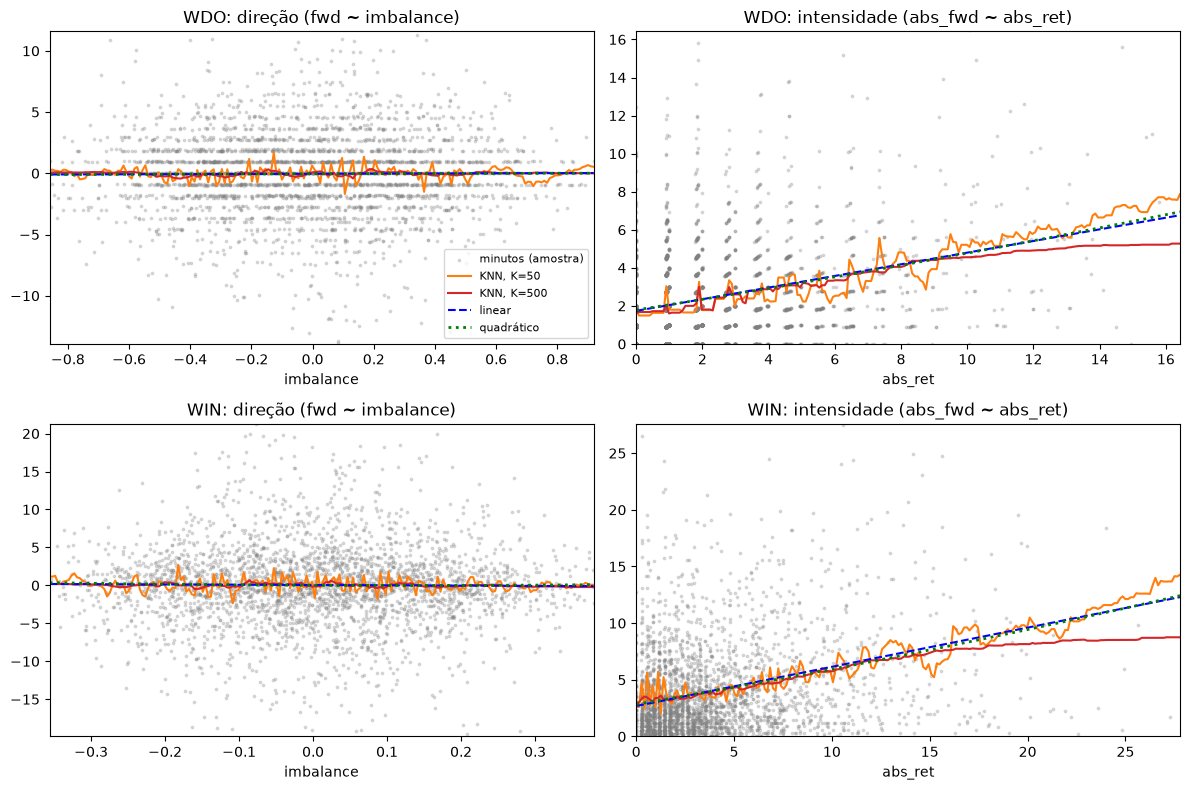

In [4]:
pares = [("imbalance", "fwd", "direção"), ("abs_ret", "abs_fwd", "intensidade")]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, root in enumerate(dados):
    tr = treino[root]
    for j, (x, y, nome) in enumerate(pares):
        ax = axes[i, j]
        lo, hi = tr[x].quantile([0.005, 0.995])
        amostra = tr.sample(3000, random_state=0)
        ax.scatter(amostra[x], amostra[y], s=3, alpha=0.25, color="gray", label="minutos (amostra)")
        grade = pd.DataFrame({x: np.linspace(lo, hi, 200)})
        for k, cor in [(50, "tab:orange"), (500, "tab:red")]:
            ax.plot(grade[x], KNeighborsRegressor(k).fit(tr[[x]], tr[y]).predict(grade), color=cor, label=f"KNN, K={k}")
        ax.plot(grade[x], LinearRegression().fit(tr[[x]], tr[y]).predict(grade), "b--", label="linear")
        ax.plot(grade[x], quadratico().fit(tr[[x]], tr[y]).predict(grade), "g:", lw=2, label="quadrático")
        ax.set_xlim(lo, hi)
        ax.set_ylim(*tr[y].quantile([0.005, 0.995]))
        ax.set_title(f"{root}: {nome} ({y} ~ {x})")
        ax.set_xlabel(x)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "ch02_fx.png", dpi=110)

In [5]:
rows = []
for root in dados:
    for x, y, nome in pares:
        rows.append({"ativo": root, "alvo": nome, "feature": x,
                     "desvio-padrão do alvo (bps)": teste[root][y].std(),
                     "R² fora da amostra, linear (%)": 100 * (1 - mse_rel(LinearRegression(), [x], y, root)),
                     "R² fora da amostra, quadrático (%)": 100 * (1 - mse_rel(quadratico(), [x], y, root)),
                     "R² fora da amostra, KNN K=500 (%)": 100 * (1 - mse_rel(KNeighborsRegressor(500), [x], y, root))})
pd.DataFrame(rows).set_index(["ativo", "alvo"]).round(2)

feature  desvio-padrão do alvo (bps)  \
ativo alvo                                                  
WDO   direção      imbalance                         3.63   
      intensidade    abs_ret                         2.69   
WIN   direção      imbalance                         4.03   
      intensidade    abs_ret                         2.83   

                   R² fora da amostra, linear (%)  \
ativo alvo                                          
WDO   direção                               -0.03   
      intensidade                            7.46   
WIN   direção                                0.04   
      intensidade                           13.00   

                   R² fora da amostra, quadrático (%)  \
ativo alvo                                              
WDO   direção                                   -0.03   
      intensidade                                7.93   
WIN   direção                                    0.02   
      intensidade                               13.26   

                   R² fora da amostra, KNN K=500 (%)  
ativo alvo                                            
WDO   direção                                  -0.35  
      intensidade                               4.70  
WIN   direção                                  -0.38  
      intensidade                              13.01

Como é a forma real da relação na intensidade? Médias por faixa de `abs_ret` (dos 50% menores ao 0,1% maior), comparadas com o que a reta, a parábola e o KNN com K=500 preveem para cada faixa:

In [6]:
rows = {}
for root in dados:
    tr = treino[root]
    faixa = pd.qcut(tr["abs_ret"], [0, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 1], duplicates="drop")
    g = tr.groupby(faixa, observed=True).agg(minutos=("abs_fwd", "size"), abs_ret_medio=("abs_ret", "mean"),
                                             abs_fwd_medio=("abs_fwd", "mean"))
    x = g[["abs_ret_medio"]].rename(columns={"abs_ret_medio": "abs_ret"})
    for nome, modelo in [("reta", LinearRegression()), ("parábola", quadratico()), ("KNN, K=500", KNeighborsRegressor(500))]:
        g[nome] = modelo.fit(tr[["abs_ret"]], tr["abs_fwd"]).predict(x)
    g.index = ["50% menores", "50% a 75%", "75% a 90%", "90% a 95%", "95% a 99%", "99% a 99,9%", "0,1% maiores"]
    rows[root] = g
pd.concat(rows, names=["ativo", "faixa de abs_ret"]).round(2)

minutos  abs_ret_medio  abs_fwd_medio   reta  \
ativo faixa de abs_ret                                                 
WDO   50% menores          4235           0.76           2.00   1.98   
      50% a 75%            2118           2.42           2.45   2.48   
      75% a 90%            1269           4.35           2.97   3.07   
      90% a 95%             423           6.46           3.63   3.72   
      95% a 99%             339           9.47           4.76   4.64   
      99% a 99,9%            76          16.10           7.47   6.66   
      0,1% maiores            9          28.14          10.78  10.35   
WIN   50% menores          4196           1.23           3.28   3.12   
      50% a 75%            2098           3.86           3.87   4.03   
      75% a 90%            1258           7.01           4.79   5.12   
      90% a 95%             420          10.91           6.28   6.46   
      95% a 99%             336          15.81           8.04   8.16   
      99% a 99,9%            75          28.29          14.56  12.47   
      0,1% maiores            9          62.38          23.79  24.26   

                        parábola  KNN, K=500  
ativo faixa de abs_ret                        
WDO   50% menores           2.00        1.72  
      50% a 75%             2.47        2.44  
      75% a 90%             3.03        3.04  
      90% a 95%             3.66        3.65  
      95% a 99%             4.60        4.50  
      99% a 99,9%           6.83        5.22  
      0,1% maiores         11.41        5.30  
WIN   50% menores           3.20        3.60  
      50% a 75%             3.99        3.88  
      75% a 90%             4.97        4.66  
      90% a 95%             6.24        6.22  
      95% a 99%             7.93        7.62  
      99% a 99,9%          12.63        8.75  
      0,1% maiores         28.56        9.07

**O que os números mostram**
- **Direção:** a curva estimada de $f$ é praticamente plana em zero. O R² fora da amostra é ~0 na linear e na quadrática e negativo no KNN. Com essa feature, quase todo o erro é **irredutível**.
- **Intensidade:** $f$ cresce com `abs_ret`, ou seja, minuto agitado tende a ser seguido de minuto agitado. Com uma única feature, o R² fora da amostra fica em 7–8% no WDO e ~13% no WIN. No notebook 00, essa memória apareceu como **aglomeração de volatilidade**: a autocorrelação do \|retorno\| no lag 1 é 0,29 (WDO) e 0,33 (WIN). Lá, ela foi medida nos mesmos dados; aqui, o modelo aprende essa relação no treino e a usa para prever minutos do teste.
- **Reta, parábola e vizinhos:** é a mesma sequência dos slides (linear → quadrático). Na intensidade, a quadrática ganha um pouco da reta (7,9% contra 7,5% no WDO; 13,3% contra 13,0% no WIN). O KNN com K=500 empata com a reta no WIN (13,0%) e perde no WDO (4,7%).
- **O KNN achata nos extremos; os dados não.** Nas médias por faixa de `abs_ret` (tabela acima), a relação acompanha a reta até os \|retornos\| mais altos, e a parábola tem até uma leve curvatura para cima. O KNN com K=500 subestima os extremos: no WIN, para a faixa do 0,1% maior (\|retorno\| médio de 62 bps), ele prevê 9 bps, enquanto a média real é 24 bps. Na borda dos dados, os 500 vizinhos mais próximos vêm quase todos de \|retornos\| menores. É o **viés de borda** do KNN, e ajuda a explicar por que ele perde para a reta no WDO.
- No WDO os pontos formam faixas porque o preço anda em ticks de 0,5 ponto (~0,9 bp), então |ret| só assume alguns valores.

"Irredutível" é sempre **relativo ao X escolhido**. Com outra informação (o livro de ofertas, por exemplo), parte desse erro poderia virar redutível. No mesmo mercado e com features parecidas, um alvo é quase todo irredutível e o outro é parcialmente redutível: escolher o alvo já faz parte da modelagem.

## 2. Maldição da dimensionalidade (aula 2.2)

O KNN só funciona se houver vizinhos *perto* de cada ponto. Cada feature nova é uma dimensão a mais, e em muitas dimensões até os vizinhos mais próximos ficam longe.

**Geometria (slide "The curse of dimensionality"):** para a média ter pouca variância, ela precisa de uma fração razoável dos dados, por exemplo 10%. Qual é o raio da vizinhança que contém os 10% de minutos mais parecidos com um dado minuto? O raio é medido como fração da distância típica entre dois minutos quaisquer. Perto de 0, a vizinhança é local; perto de 1, ela já "pega tudo" e deixa de ser local.

Comparamos as features reais (padronizadas) com pontos uniformes num cubo, que é o caso do slide.

,1,2,3,5,9
WDO (features reais),0.03,0.34,0.43,0.53,0.63
WIN (features reais),0.13,0.34,0.42,0.49,0.58
uniforme no cubo,0.17,0.36,0.50,0.63,0.74


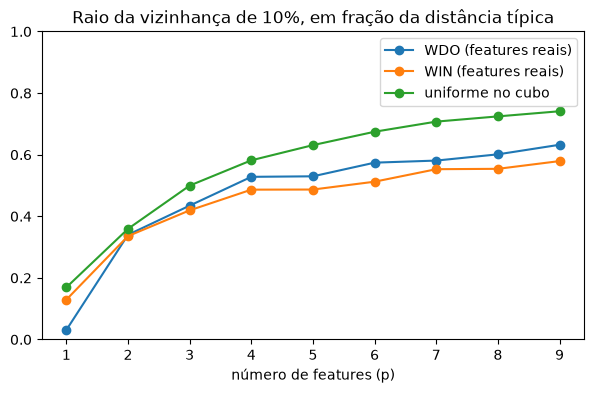

In [7]:
ordem = ["abs_ret", "log_vol", "minuto", "imbalance", "ret", "abs_ret_l1", "ret_l1", "abs_ret_l2", "ret_l2"]
geo_rng = np.random.default_rng(0)


def raio_10pct(M, n_consultas=300):
    k = len(M) // 10
    q = geo_rng.choice(len(M), n_consultas, replace=False)
    raio = NearestNeighbors(n_neighbors=k).fit(M).kneighbors(M[q])[0][:, -1]
    a, b = geo_rng.choice(len(M), 5000), geo_rng.choice(len(M), 5000)
    return np.median(raio) / np.median(np.linalg.norm(M[a] - M[b], axis=1))


geo = {}
for root in dados:
    tr = treino[root]
    geo[f"{root} (features reais)"] = {p: raio_10pct(StandardScaler().fit_transform(tr[ordem[:p]])) for p in range(1, 10)}
geo["uniforme no cubo"] = {p: raio_10pct(geo_rng.random((len(treino["WIN"]), p))) for p in range(1, 10)}
geo = pd.DataFrame(geo)
ax = geo.plot(marker="o", figsize=(7, 4), title="Raio da vizinhança de 10%, em fração da distância típica")
ax.set_xlabel("número de features (p)")
ax.set_ylim(0, 1)
geo.loc[[1, 2, 3, 5, 9]].round(2).T

**O que os números mostram**
- Com 1 feature, a vizinhança de 10% é bem local: o raio é 3–17% da distância típica entre dois minutos. Com 9 features, o raio passa de 58% (WIN) e 63% (WDO). Os "vizinhos" já são quase tão diferentes quanto dois minutos quaisquer, e a média deixa de ser local.
- Os dados reais sofrem um pouco menos que o cubo uniforme (74% com p=9) porque as features são correlacionadas entre si (por exemplo, `abs_ret` e `abs_ret_l1`). Na prática, elas ocupam menos dimensões do que parecem.
- No WDO com 1 feature, o raio é quase zero (3%) porque `abs_ret` só assume alguns valores (efeito do tick). Muitos minutos ficam *exatamente* no mesmo ponto.

**Experimento com features inúteis:** alvo = intensidade (`abs_fwd`), uma feature útil (`abs_ret`) e *m* features de puro ruído aleatório. O KNN dá o mesmo peso a todas as dimensões. A regressão linear é um modelo **estruturado**: ela consegue dar coeficiente ~0 ao ruído.

WDO               WIN       
                      KNN, K=500 linear KNN, K=500 linear
features de ruído (m)                                    
0                            4.7    7.5       13.0   13.0
1                            5.4    7.5       14.2   12.9
2                            5.3    7.5       13.9   12.9
5                            4.8    7.5       13.6   12.5
10                           4.2    7.5       12.0   12.4
20                           3.6    7.3       10.1   12.2
50                           2.7    7.4        8.1   11.4

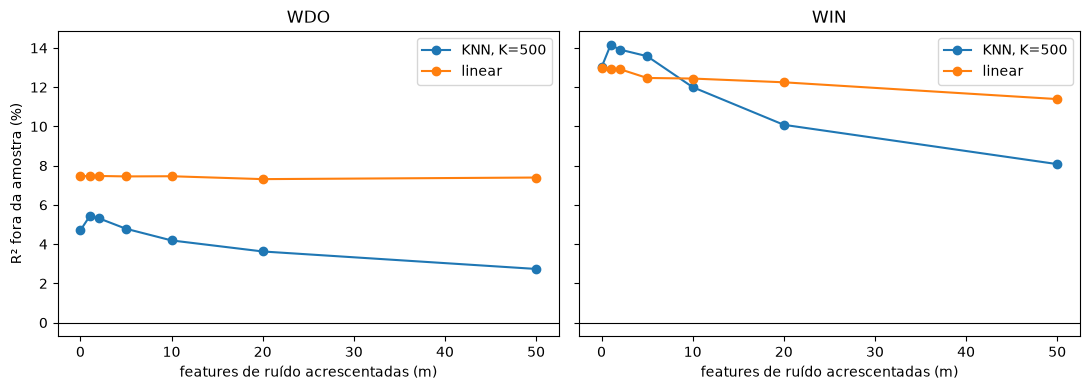

In [8]:
ms = [0, 1, 2, 5, 10, 20, 50]
ruido_tab = {}
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, root in zip(axes, dados):
    tr, te = treino[root].copy(), teste[root].copy()
    for i in range(max(ms)):
        tr[f"ruido{i}"], te[f"ruido{i}"] = rng.standard_normal(len(tr)), rng.standard_normal(len(te))
    res = {}
    for m in ms:
        cols = ["abs_ret"] + [f"ruido{i}" for i in range(m)]
        res[m] = {"KNN, K=500": 100 * (1 - mse_rel(knn(500), cols, "abs_fwd", root, tr, te)),
                  "linear": 100 * (1 - mse_rel(make_pipeline(StandardScaler(), LinearRegression()), cols, "abs_fwd", root, tr, te))}
    ruido_tab[root] = pd.DataFrame(res).T
    ruido_tab[root].plot(ax=ax, marker="o", title=root)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("features de ruído acrescentadas (m)")
axes[0].set_ylabel("R² fora da amostra (%)")
plt.tight_layout()
pd.concat(ruido_tab, axis=1).round(1).rename_axis("features de ruído (m)")

**O que os números mostram**
- O KNN perde R² conforme o ruído entra: de 4,7% para 2,7% no WDO e de 13,0% para 8,1% no WIN, com 50 features de ruído. A linear quase não se mexe: de 7,5% para 7,4% e de 13,0% para 11,4%.
- **Por quê:** o KNN mede a distância em todas as dimensões com o mesmo peso. Com 50 dimensões de ruído, os "vizinhos" passam a ser escolhidos quase só pelo ruído. A linear estima um coeficiente por feature e dá ~0 ao ruído. Ela perde um pouco porque cada coeficiente estimado carrega alguma variância.
- Com uma feature, o KNN empata com a linear no WIN e perde no WDO (seção 1). Com muitas, a linear ganha nos dois. É o trade-off da aula 2.2 entre modelo **estruturado** (paramétrico) e modelo **flexível**.
- Com 1 ou 2 features de ruído, o KNN chega a *melhorar* um pouco, nos dois ativos (no WIN, de 13,0% para 14,2%). É um efeito pequeno, que também apareceu com a amostra de 20 pregões, e que se inverte a partir de 5 features de ruído.

## 3. Flexibilidade, erro de treino e erro de teste (aula 2.3)

No KNN, a flexibilidade é controlada por K. **K pequeno** (média de poucos vizinhos) segue cada detalhe dos dados: é muito flexível. **K grande** suaviza tudo: é pouco flexível. O eixo horizontal usa 1/K, então a flexibilidade cresce para a direita, como nos gráficos do livro.

Aqui o modelo usa as 9 features. A linha tracejada é a regressão linear com as mesmas features.

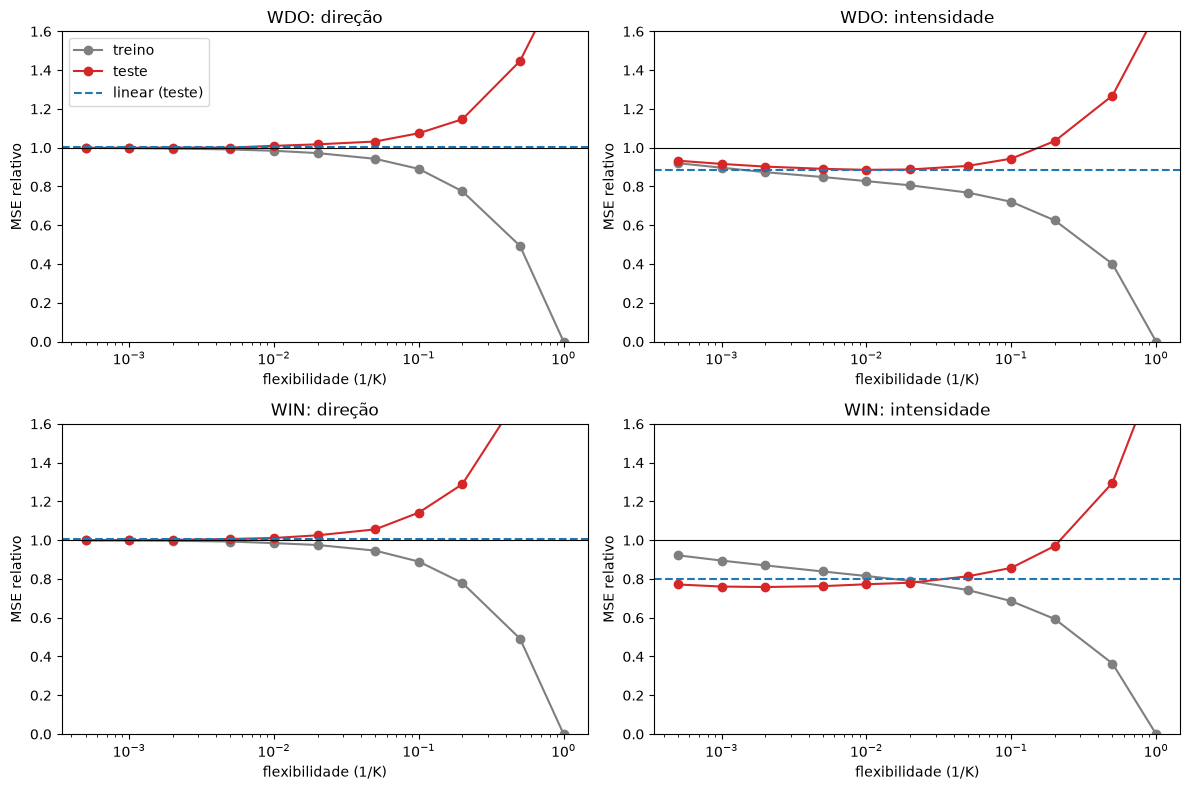

In [9]:
Ks = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
curvas = {}
for i, root in enumerate(dados):
    tr, te = treino[root], teste[root]
    for j, (alvo, nome) in enumerate([("fwd", "direção"), ("abs_fwd", "intensidade")]):
        ingenuo_tr = tr[alvo].var(ddof=0)
        ingenuo_te = ((te[alvo] - tr[alvo].mean()) ** 2).mean()
        rows = {}
        for k in Ks:
            m = knn(k).fit(tr[FEATURES], tr[alvo])
            rows[k] = {"treino": ((tr[alvo] - m.predict(tr[FEATURES])) ** 2).mean() / ingenuo_tr,
                       "teste": ((te[alvo] - m.predict(te[FEATURES])) ** 2).mean() / ingenuo_te}
        c = pd.DataFrame(rows).T
        curvas[(root, nome)] = c
        ax = axes[i, j]
        ax.plot(1 / c.index, c["treino"], "o-", color="tab:gray", label="treino")
        ax.plot(1 / c.index, c["teste"], "o-", color="tab:red", label="teste")
        ax.axhline(mse_rel(LinearRegression(), FEATURES, alvo, root), color="tab:blue", ls="--", label="linear (teste)")
        ax.axhline(1, color="k", lw=0.8)
        ax.set_xscale("log")
        ax.set_ylim(0, 1.6)
        ax.set_title(f"{root}: {nome}")
        ax.set_xlabel("flexibilidade (1/K)")
        ax.set_ylabel("MSE relativo")
axes[0, 0].legend()
plt.tight_layout()
fig.savefig(FIG / "ch02_flexibilidade.png", dpi=110)

In [10]:
melhor = pd.DataFrame({f"{r} · {n}": {"K com menor erro de teste": c["teste"].idxmin(),
                                         "R² fora da amostra no melhor K (%)": 100 * (1 - c["teste"].min()),
                                         "R² fora da amostra com K=1 (%)": 100 * (1 - c.loc[1, "teste"])}
                       for (r, n), c in curvas.items()}).T
melhor.round(2)

,K com menor erro de teste,R² fora da amostra no melhor K (%),R² fora da amostra com K=1 (%)
WDO · direção,2000.0,0.10,-89.29
WDO · intensidade,100.0,11.44,-69.28
WIN · direção,2000.0,0.05,-145.23
WIN · intensidade,500.0,24.16,-87.78


**O que os números mostram**
- **Treino:** o MSE de treino sempre cai com a flexibilidade e chega a zero com K=1, porque cada ponto é vizinho de si mesmo. Erro de treino não serve para escolher modelo.
- **Teste, direção:** o melhor é o modelo menos flexível (K=2.000), e mesmo assim o R² fica em ~0. Qualquer flexibilidade só piora: com K=1, o R² é de −89% no WDO e −145% no WIN. A linear empata com o chute ingênuo.
- **Teste, intensidade:** aparece o "U" das aulas, com ótimo em K=100 no WDO e K=500 no WIN. O R² chega a 11% no WDO e 24% no WIN, acima do da seção 1 porque agora entram horário e volume. A linear com as mesmas 9 features fica em 11,5% no WDO (empata com o melhor KNN) e 20% no WIN.
- ⚠️ O melhor K foi escolhido olhando o teste, o que deixa os números do KNN otimistas.

### 3.1 Decompondo o erro em viés² + variância + irredutível

Com dados reais não dá para separar viés e variância, porque o $f$ verdadeiro é desconhecido. A saída é uma **simulação** em que $f$ é conhecido, mas o mais realista possível:
- **X:** valores reais da feature (WIN, período de treino);
- **f verdadeiro:** o $f$ estimado na seção 1 (linear para a direção, KNN K=500 para a intensidade). Para a intensidade, é um $f$ hipotético e plausível, não o real: a curva do KNN achata nos extremos por viés de borda (seção 1);
- **ε:** resíduos reais sorteados com reposição, o que preserva as caudas gordas.

Repetimos 200 vezes: sorteia um conjunto de treino de 2.000 minutos, ajusta o modelo e prevê em 300 pontos fixos. Em cada ponto, o **viés** é a diferença entre a previsão média e o $f$ verdadeiro, e a **variância** é o quanto a previsão muda de um conjunto de treino para outro.

Simplificação: os resíduos são sorteados independentemente de X. Nos dados reais, minutos agitados têm resíduos maiores.

Os slides mostram três casos (figuras 2.9 a 2.12): um $f$ quase linear, em que a reta vence; um $f$ curvo; e um $f$ **ondulado com pouco ruído**, em que o modelo mais flexível vence. Os dois primeiros saem dos nossos dados. O terceiro é **hipotético** e responde à pergunta: como o mercado teria que ser para valer a pena usar um modelo muito flexível? Ele usa o $f$ da intensidade com uma ondulação somada ($1{,}5 \cdot \sin(2\pi x / 3)$) e o ruído dividido por 10.

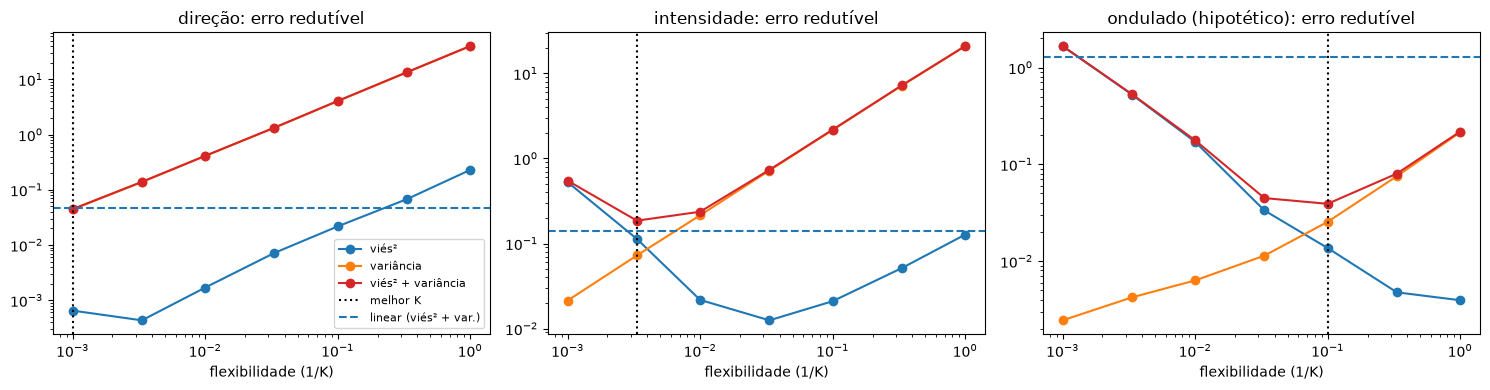

In [11]:
def decompor(x, f_x, eps, Ks, n=2000, reps=200, n_pontos=300, seed=0):
    rng = np.random.default_rng(seed)
    idx0 = rng.choice(len(x), n_pontos, replace=False)
    x0, f0 = x[idx0].reshape(-1, 1), f_x[idx0]
    modelos = {f"KNN K={k}": (lambda k=k: KNeighborsRegressor(k)) for k in Ks}
    modelos["linear"] = LinearRegression
    prev = {nome: np.empty((reps, n_pontos)) for nome in modelos}
    for r in range(reps):
        i = rng.choice(len(x), n)
        xs, ys = x[i].reshape(-1, 1), f_x[i] + rng.choice(eps, n)   # f verdadeiro + ruído real sorteado
        for nome, cria in modelos.items():
            prev[nome][r] = cria().fit(xs, ys).predict(x0)
    out = {nome: {"viés²": ((p.mean(0) - f0) ** 2).mean(), "variância": p.var(0).mean()} for nome, p in prev.items()}
    out = pd.DataFrame(out).T
    out["irredutível"] = eps.var()
    out["erro de teste esperado"] = out.sum(axis=1)
    return out


tr = treino["WIN"]
Ks_sim = [1, 3, 10, 30, 100, 300, 1000]
decomp = {}
for x, y, nome in pares:
    xv, yv = tr[x].to_numpy(), tr[y].to_numpy()
    verdadeiro = (LinearRegression() if nome == "direção" else KNeighborsRegressor(500)).fit(xv.reshape(-1, 1), yv)
    f_x = verdadeiro.predict(xv.reshape(-1, 1))
    decomp[nome] = decompor(xv, f_x, yv - f_x, Ks_sim)
    if nome == "intensidade":   # cenário hipotético: f ondulado, pouco ruído
        f_ond = f_x + 1.5 * np.sin(2 * np.pi * xv / 3)
        decomp["ondulado (hipotético)"] = decompor(xv, f_ond, (yv - f_x) / 10, Ks_sim)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
flex = 1 / np.array(Ks_sim)
for ax, (nome, d) in zip(axes, decomp.items()):
    knn_d = d.drop(index="linear")
    total = knn_d["viés²"] + knn_d["variância"]
    ax.plot(flex, knn_d["viés²"], "o-", label="viés²")
    ax.plot(flex, knn_d["variância"], "o-", label="variância")
    ax.plot(flex, total, "o-", color="tab:red", label="viés² + variância")
    ax.axvline(flex[total.argmin()], color="k", ls=":", label="melhor K")
    ax.axhline(d.loc["linear", "viés²"] + d.loc["linear", "variância"], color="tab:blue", ls="--", label="linear (viés² + var.)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{nome}: erro redutível")
    ax.set_xlabel("flexibilidade (1/K)")
axes[0].legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "ch02_vies_variancia.png", dpi=110)

In [12]:
pd.concat(decomp).round(4)

viés²  variância  irredutível  \
direção               KNN K=1     0.2292    39.9969      40.2449   
                      KNN K=3     0.0678    13.4376      40.2449   
                      KNN K=10    0.0217     4.0391      40.2449   
                      KNN K=30    0.0072     1.3305      40.2449   
                      KNN K=100   0.0017     0.4103      40.2449   
                      KNN K=300   0.0004     0.1388      40.2449   
                      KNN K=1000  0.0006     0.0441      40.2449   
                      linear      0.0002     0.0469      40.2449   
intensidade           KNN K=1     0.1273    20.8570      21.0796   
                      KNN K=3     0.0515     7.2000      21.0796   
                      KNN K=10    0.0210     2.1597      21.0796   
                      KNN K=30    0.0125     0.7222      21.0796   
                      KNN K=100   0.0217     0.2148      21.0796   
                      KNN K=300   0.1133     0.0724      21.0796   
                      KNN K=1000  0.5272     0.0214      21.0796   
                      linear      0.1167     0.0233      21.0796   
ondulado (hipotético) KNN K=1     0.0039     0.2140       0.2108   
                      KNN K=3     0.0048     0.0754       0.2108   
                      KNN K=10    0.0137     0.0254       0.2108   
                      KNN K=30    0.0334     0.0114       0.2108   
                      KNN K=100   0.1708     0.0063       0.2108   
                      KNN K=300   0.5260     0.0042       0.2108   
                      KNN K=1000  1.6633     0.0024       0.2108   
                      linear      1.2714     0.0047       0.2108   

                                  erro de teste esperado  
direção               KNN K=1                    80.4709  
                      KNN K=3                    53.7503  
                      KNN K=10                   44.3057  
                      KNN K=30                   41.5826  
                      KNN K=100                  40.6569  
                      KNN K=300                  40.3841  
                      KNN K=1000                 40.2897  
                      linear                     40.2920  
intensidade           KNN K=1                    42.0638  
                      KNN K=3                    28.3311  
                      KNN K=10                   23.2603  
                      KNN K=30                   21.8143  
                      KNN K=100                  21.3161  
                      KNN K=300                  21.2653  
                      KNN K=1000                 21.6281  
                      linear                     21.2195  
ondulado (hipotético) KNN K=1                     0.4287  
                      KNN K=3                     0.2910  
                      KNN K=10                    0.2499  
                      KNN K=30                    0.2556  
                      KNN K=100                   0.3879  
                      KNN K=300                   0.7410  
                      KNN K=1000                  1.8765  
                      linear                      1.4869

**O que os números mostram** (unidade: bps²; os três casos correspondem às figuras 2.10, 2.9 e 2.11 dos slides)
- **Direção (f quase plano, muito ruído):** o viés² é minúsculo em qualquer K. O erro redutível é praticamente só variância, e a variância cai com K. O melhor é o modelo mais rígido: KNN com K=1.000 ou a linear, os dois com 40,29, contra um irredutível de 40,24. **Quando não há sinal, flexibilidade é só custo.**
- **Intensidade (f levemente curvo, muito ruído):** o "U" clássico. Indo de K=1.000 para K=30, o viés² cai de 0,53 para 0,013, mas a variância sobe de 0,02 para 0,72 (e chega a 21 com K=1). O mínimo do KNN fica em K≈300. A linear fica até um pouco melhor que o melhor KNN (21,22 contra 21,27): o pouco viés que ela tem (0,12) é compensado pela variância quase nula.
- **Ondulado (hipotético, pouco ruído):** aqui a flexibilidade compensa. O melhor KNN é o de K=10 (0,25), e a linear (1,49) erra muito, porque o viés² dela é 1,27: uma reta não segue as ondas. Para um modelo flexível valer a pena, o $f$ precisa ter forma complicada **e** o ruído precisa ser pequeno em relação a ela. Nos nossos dados de 1 minuto não acontece nem uma coisa nem outra.
- **Escala:** nos dois casos reais, o erro irredutível (40 e 21) é de cem a mil vezes maior que viés² + variância no melhor modelo (0,04 e 0,14). Em mercado, o teto de quanto um modelo pode melhorar é dado pelo erro irredutível, não pelo modelo.

## 4. Classificação (aula 2.4)

Duas perguntas de classificação para o próximo minuto:
- **direção:** sobe, fica parado ou cai?
- **agitado:** o |retorno| vai ficar acima da mediana do treino?

A medida é a **taxa de erro** no teste (fração de classificações erradas), comparada com o **chute ingênuo**: prever sempre a classe mais comum no treino.

⚠️ O "melhor K" das tabelas foi escolhido olhando o próprio teste, o que deixa o resultado otimista. O correto seria escolher K num conjunto de validação separado, sem olhar o teste.

In [13]:
def classes(d, mediana_treino):
    return {"direção": np.sign(d["fwd"]).map({1: "sobe", 0: "parado", -1: "cai"}),
            "agitado": (d["abs_fwd"] > mediana_treino).map({True: "agitado", False: "calmo"})}


rows, curvas_cls = [], {}
for root in dados:
    tr, te = treino[root], teste[root]
    med = tr["abs_fwd"].median()
    y_tr, y_te = classes(tr, med), classes(te, med)
    for tarefa in ["direção", "agitado"]:
        freq = y_tr[tarefa].value_counts(normalize=True)
        ingenuo = (y_te[tarefa] != freq.idxmax()).mean()
        erros = {}
        for k in Ks[1:]:
            m = make_pipeline(StandardScaler(), KNeighborsClassifier(k)).fit(tr[FEATURES], y_tr[tarefa])
            erros[k] = {"treino": (m.predict(tr[FEATURES]) != y_tr[tarefa]).mean(),
                        "teste": (m.predict(te[FEATURES]) != y_te[tarefa]).mean()}
        c = pd.DataFrame(erros).T
        curvas_cls[(root, tarefa)] = (c, ingenuo)
        rows.append({"ativo": root, "tarefa": tarefa,
                     "classes no treino (%)": ", ".join(f"{cl} {100 * p:.0f}" for cl, p in freq.items()),
                     "erro do chute ingênuo (%)": 100 * ingenuo,
                     "erro-padrão da taxa (pontos)": 100 * np.sqrt(ingenuo * (1 - ingenuo) / len(te)),
                     "erro de 'sempre calmo' (%)": 100 * (y_te[tarefa] != "calmo").mean() if tarefa == "agitado" else np.nan,
                     "melhor K": c["teste"].idxmin(),
                     "erro do KNN no melhor K (%)": 100 * c["teste"].min()})
pd.DataFrame(rows).set_index(["ativo", "tarefa"]).round(1)

classes no treino (%)  erro do chute ingênuo (%)  \
ativo tarefa                                                           
WDO   direção  sobe 42, cai 42, parado 16                       55.0   
      agitado        calmo 50, agitado 50                       40.7   
WIN   direção   sobe 49, cai 48, parado 3                       51.0   
      agitado        agitado 50, calmo 50                       60.9   

               erro-padrão da taxa (pontos)  erro de 'sempre calmo' (%)  \
ativo tarefa                                                              
WDO   direção                           0.8                         NaN   
      agitado                           0.8                        40.7   
WIN   direção                           0.8                         NaN   
      agitado                           0.8                        39.1   

               melhor K  erro do KNN no melhor K (%)  
ativo tarefa                                          
WDO   direção       200                         55.1  
      agitado      2000                         36.5  
WIN   direção      1000                         49.2  
      agitado      1000                         35.4

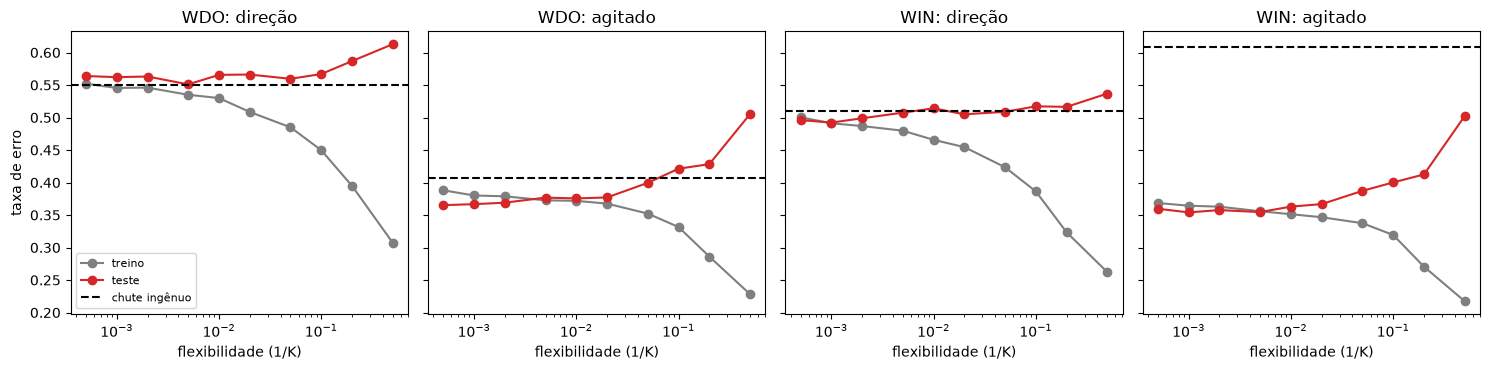

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, ((root, tarefa), (c, ingenuo)) in zip(axes, curvas_cls.items()):
    ax.plot(1 / c.index, c["treino"], "o-", color="tab:gray", label="treino")
    ax.plot(1 / c.index, c["teste"], "o-", color="tab:red", label="teste")
    ax.axhline(ingenuo, color="k", ls="--", label="chute ingênuo")
    ax.set_xscale("log")
    ax.set_title(f"{root}: {tarefa}")
    ax.set_xlabel("flexibilidade (1/K)")
axes[0].set_ylabel("taxa de erro")
axes[0].legend(fontsize=8)
plt.tight_layout()

**O que os números mostram**
- **Direção:** no WDO, o KNN (55,1% de erro) não bate o chute ingênuo (55,0%). No WIN, a diferença é de 1,8 ponto (49,2% contra 51,0%) em ~3.900 minutos, cerca de 2 erros-padrão (o erro-padrão de uma taxa assim é ~0,8 ponto). Só que o K foi escolhido entre 10 valores olhando o próprio teste, e com 10 tentativas é fácil uma delas chegar a 2 erros-padrão por acaso. Não é evidência de sinal.
- O WDO tem 16% de minutos "parados", contra só 3% no WIN: o tick do WDO é grande em relação aos movimentos de 1 minuto.
- **Agitado no WDO:** o KNN erra 36,5%, contra 40,7% do chute ingênuo ("sempre calmo").
- **Agitado no WIN:** a tabela mostra um chute ingênuo de 60,9%, e isso é um detalhe que engana. No treino, as duas classes ficaram empatadas em 50%, e "agitado" ganhou por décimos. Então o chute ingênuo passa a ser "sempre agitado", e num teste mais calmo ele erra 61%. A comparação justa é com "sempre calmo", que erra 39,1%. Contra ela, o KNN (35,4%) ganha ~4 pontos, parecido com o WDO.
- **O teste foi mais calmo que o treino:** só 39–41% dos minutos do teste ficaram acima da mediana de agitação do treino.
- O ganho em classificação parece pequeno perto do R² de 11–24% da regressão. Uma explicação provável é que cortar na mediana joga fora a informação de magnitude, e muitos minutos ficam perto da fronteira entre as classes.
- As curvas repetem o padrão da regressão: o erro de treino cai com a flexibilidade e o de teste sobe.

### 4.1 A incerteza de cada classificação

Os slides listam três objetivos da classificação: classificar, **medir a incerteza de cada classificação** e entender o papel de cada feature. Para a incerteza, em vez de só "agitado/calmo", olhamos a probabilidade estimada $\hat p(\text{agitado} \mid x)$, que no KNN é a fração de vizinhos agitados.

Se as probabilidades forem confiáveis (**calibradas**), entre os minutos com $\hat p \approx 0{,}7$ uns 70% deveriam ser agitados de fato. Abaixo: KNN com K=500 e as 9 features, minutos do teste agrupados por faixa de $\hat p$.

In [15]:
faixas_p = [0, 0.2, 0.35, 0.5, 0.65, 0.8, 1]
tabs = {}
for root in dados:
    tr, te = treino[root], teste[root]
    med = tr["abs_fwd"].median()
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(500)).fit(tr[FEATURES], tr["abs_fwd"] > med)
    p_hat = m.predict_proba(te[FEATURES])[:, 1]
    g = pd.DataFrame({"p_hat": p_hat, "agitado": te["abs_fwd"].to_numpy() > med})
    g["faixa"] = pd.cut(g["p_hat"], faixas_p, include_lowest=True)
    tabs[root] = g.groupby("faixa", observed=True).agg(minutos=("agitado", "size"), p_hat_medio=("p_hat", "mean"),
                                                       agitados_de_fato=("agitado", "mean"))
pd.concat(tabs, axis=1).round(2)

WDO                                  WIN              \
            minutos p_hat_medio agitados_de_fato minutos p_hat_medio   
faixa                                                                  
(0.2, 0.35]     674        0.32             0.19    1099        0.29   
(0.35, 0.5]    1543        0.42             0.35    1270        0.42   
(0.5, 0.65]    1623        0.57             0.53    1481        0.57   
(0.65, 0.8]     122        0.68             0.74      73        0.67   

                              
            agitados_de_fato  
faixa                         
(0.2, 0.35]             0.21  
(0.35, 0.5]             0.36  
(0.5, 0.65]             0.54  
(0.65, 0.8]             0.67

**O que os números mostram**
- **A ordem está certa:** quanto maior o $\hat p$, maior a fração de minutos agitados de fato: de 19% a 74% no WDO e de 21% a 67% no WIN, da faixa mais baixa à mais alta. O modelo separa bem os minutos mais e menos arriscados.
- **O nível erra nas faixas baixas:** no WDO, entre os minutos com $\hat p \approx 0{,}32$, só 19% foram agitados; com $\hat p \approx 0{,}42$, 35%. As probabilidades exageram o risco porque foram aprendidas num período mais agitado (de novo a mudança de regime). Na faixa mais alta, o nível bate ou até fica abaixo do realizado.
- Quase nenhum minuto tem $\hat p$ acima de 0,65 (122 no WDO e 73 no WIN) ou abaixo de 0,2 (nenhum). O modelo raramente tem certeza, o que é coerente com um erro irredutível alto.
- Para usar essas probabilidades (por exemplo, para dimensionar risco), seria preciso **recalibrá-las** em dados recentes. Classificar bem e dar probabilidades confiáveis são coisas diferentes.

### 4.2 O classificador de Bayes

O classificador de Bayes escolhe a classe mais provável dado X. Ele tem o **menor erro possível** (o *erro de Bayes*), mas exige conhecer $P(Y \mid X)$, que nos dados reais é desconhecido. Com duas classes, ele escolhe "agitado" quando $p(x) > 0{,}5$, e o ponto onde $p(x) = 0{,}5$ é a **fronteira de decisão de Bayes**.

Na simulação, $p(x)$ é conhecido. A tarefa é "agitado" no WIN, com X = `abs_ret`, e a probabilidade verdadeira $p(x)$ vem de um KNN suavizado (K=500) nos dados reais. Sorteamos rótulos com essa probabilidade, treinamos o KNN em 2.000 minutos e medimos o erro em 200.000.

Fronteira de Bayes: 'agitado' quando abs_ret > 3.45 bps


,KNN K=1,KNN K=3,KNN K=10,KNN K=30,KNN K=100,KNN K=300,KNN K=1000,Bayes,ingênuo
erro (%),47.6,46.8,45.0,43.4,42.7,42.3,42.6,42.0,49.7


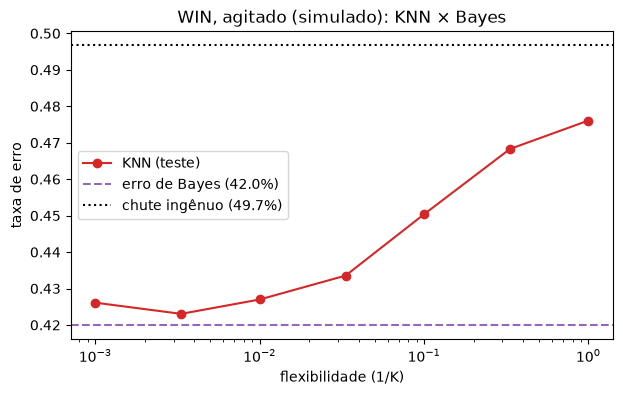

In [16]:
rng = np.random.default_rng(1)
tr = treino["WIN"]
x = tr[["abs_ret"]].to_numpy()
y_real = (tr["abs_fwd"] > tr["abs_fwd"].median()).astype(int)
p_verdadeiro = KNeighborsRegressor(500).fit(x, y_real)
p = p_verdadeiro.predict(x)   # P(agitado | x) "verdadeira"

grade = np.linspace(0, 20, 401).reshape(-1, 1)
fronteira = grade[p_verdadeiro.predict(grade) > 0.5][0, 0]
print(f"Fronteira de Bayes: 'agitado' quando abs_ret > {fronteira:.2f} bps")

i_tr, i_te = rng.choice(len(x), 2000), rng.choice(len(x), 200_000)
y_tr_sim, y_te_sim = rng.random(2000) < p[i_tr], rng.random(200_000) < p[i_te]
erro_bayes = ((p[i_te] > 0.5) != y_te_sim).mean()   # Bayes: escolhe a classe com p > 0,5
erro_ingenuo = min(y_te_sim.mean(), 1 - y_te_sim.mean())

sim = {k: (KNeighborsClassifier(k).fit(x[i_tr], y_tr_sim).predict(x[i_te]) != y_te_sim).mean() for k in Ks_sim}
ax = pd.Series(sim, name="KNN (teste)").rename(lambda k: 1 / k).plot(marker="o", logx=True, color="tab:red", figsize=(7, 4))
ax.axhline(erro_bayes, color="tab:purple", ls="--", label=f"erro de Bayes ({100 * erro_bayes:.1f}%)")
ax.axhline(erro_ingenuo, color="k", ls=":", label=f"chute ingênuo ({100 * erro_ingenuo:.1f}%)")
ax.set_xlabel("flexibilidade (1/K)")
ax.set_ylabel("taxa de erro")
ax.set_title("WIN, agitado (simulado): KNN × Bayes")
ax.legend()
pd.Series({f"KNN K={k}": 100 * e for k, e in sim.items()} | {"Bayes": 100 * erro_bayes, "ingênuo": 100 * erro_ingenuo}).round(1).to_frame("erro (%)").T

**O que os números mostram**
- **A fronteira de Bayes** é `abs_ret` ≈ 3,45 bps: acima disso, o próximo minuto tem mais chance de ser agitado do que calmo. Em uma dimensão, a "fronteira de decisão" dos slides vira um único limiar.
- O KNN nunca fica abaixo do erro de Bayes (42,0%), que é o mínimo possível com essa X. O melhor K (300) chega a 42,3%, quase lá. Com K=1, o erro vai a 47,6%, perto do chute ingênuo (49,7%). É o mesmo formato da figura 2.17 dos slides.
- Mesmo o classificador perfeito erra 42%. Com essa X, a probabilidade de o próximo minuto ser agitado raramente se afasta muito de 50%. Esse é o **erro irredutível** da classificação.

## 5. Interpretabilidade e parcimônia (slides "Some trade-offs")

Os slides listam três trade-offs: **precisão × interpretabilidade**, **ajuste bom × sobreajuste ou subajuste** (seções 3 e 4) e **parcimônia × caixa-preta**. Para o primeiro e o terceiro, comparamos no alvo intensidade:
- a **regressão linear com as 9 features**: dá para ler, porque cada coeficiente diz quanto `abs_fwd` muda (em bps) quando a feature sobe 1 desvio-padrão;
- uma **linear parcimoniosa**, só com as 3 features de maior coeficiente no treino;
- o **melhor KNN** da seção 3, que é uma caixa-preta: prevê, mas não diz por quê.

Os coeficientes aqui são só descritivos. Os testes de cada coeficiente, com erro-padrão, estão no [cap. 3](ch03_linear_regression.ipynb).

In [17]:
coefs = pd.DataFrame({root: make_pipeline(StandardScaler(), LinearRegression())
                      .fit(treino[root][FEATURES], treino[root]["abs_fwd"])[-1].coef_
                      for root in dados}, index=FEATURES)
coefs.round(2).rename_axis("coeficiente (bps por 1 desvio-padrão)")

,WDO,WIN
coeficiente (bps por 1 desvio-padrão),,
ret,-0.08,0.02
ret_l1,-0.05,-0.02
ret_l2,-0.04,0.31
abs_ret,0.40,1.13
abs_ret_l1,0.51,0.58
abs_ret_l2,0.34,0.92
imbalance,0.02,-0.05
log_vol,0.27,-0.13
minuto,-0.18,-0.56


In [18]:
comp = {}
for root in dados:
    top3 = coefs[root].abs().nlargest(3).index.tolist()
    comp[root] = {"linear, 9 features": 100 * (1 - mse_rel(LinearRegression(), FEATURES, "abs_fwd", root)),
                  "linear, 3 features": 100 * (1 - mse_rel(LinearRegression(), top3, "abs_fwd", root)),
                  "as 3 features": ", ".join(top3),
                  "melhor KNN, 9 features (seção 3)": 100 * (1 - curvas[(root, "intensidade")]["teste"].min())}
pd.DataFrame(comp).rename_axis("R² fora da amostra (%)")

,WDO,WIN
R² fora da amostra (%),,
"linear, 9 features",11.522209,19.982148
"linear, 3 features",9.395441,18.897266
as 3 features,"abs_ret_l1, abs_ret, abs_ret_l2","abs_ret, abs_ret_l2, abs_ret_l1"
"melhor KNN, 9 features (seção 3)",11.439668,24.162907


**O que os números mostram**
- **Interpretabilidade:** a linear pode ser lida. Nos dois ativos, os maiores coeficientes são os de |ret| atual e defasado: no WIN, 1 desvio-padrão a mais em `abs_ret` aumenta o `abs_fwd` previsto em 1,13 bp. O coeficiente de `minuto` é negativo, ou seja, o mercado fica mais calmo ao longo do dia. A direção (`ret`, `imbalance`) tem coeficientes ~0, coerente com a seção 1. O KNN não oferece nada parecido com essa tabela.
- **Cuidado:** o `log_vol` negativo no WIN não quer dizer que volume alto acalma o minuto seguinte. O [cap. 3](ch03_linear_regression.ipynb) (seção 2.2) mostra que é **confusão**: sozinho, o volume parece importar porque anda junto com o \|retorno\| e com o horário; com eles no modelo, o coeficiente não é significativo (p-valor 0,21).
- **Parcimônia:** só com as 3 defasagens de |ret|, a linear mantém quase todo o desempenho no WIN (18,9% contra 20,0%) e perde um pouco no WDO (9,4% contra 11,5%).
- **Preço da interpretabilidade:** no WDO, nenhum. A linear com 9 features empata com o melhor KNN (11,5% contra 11,4%). No WIN, o KNN ganha por 4 pontos (24,2% contra 20,0%), mas esse K foi escolhido no teste, então parte da vantagem é otimismo.

## Conclusões

**Amostra:** 22 pregões, de 20/10 a 19/11/2026. Treino de 20/10 a 10/11 (15 pregões) e teste de 11/11 a 19/11 (7 pregões).

1. **O erro irredutível domina.** Na *direção* do próximo minuto, nenhum modelo com essas 9 features bate o chute ingênuo de forma confiável. Na *intensidade* existe uma parte redutível real: R² fora da amostra de ~11% no WDO e ~24% no WIN.
2. **O preço da flexibilidade depende do sinal.** Sem sinal, o melhor modelo é o mais rígido, e toda flexibilidade vira variância. Com sinal fraco, aparece o "U", e a reta empata com o melhor KNN (no WDO e na simulação) ou fica perto dele (no WIN). A flexibilidade só compensa com um $f$ ondulado *e* pouco ruído, o caso hipotético da seção 3.1, que não é o dos nossos dados.
3. **A dimensionalidade cobra rápido.** Com 9 features, a vizinhança de 10% já cobre ~60% da distância típica entre minutos. Com 50 features de ruído, o KNN perde ~40% do R² e a linear quase nada.
4. **O erro de treino engana.** Com K=1, o erro de treino é zero e o de teste é o pior de todos.
5. **Classificar não é o mesmo que dar probabilidades confiáveis.** O KNN ordena bem os minutos por risco de agitação, mas superestima o nível nas faixas baixas porque aprendeu num período mais agitado.
6. **O regime muda.** O teste foi mais calmo que o treino (26/10 está no treino). Até o chute ingênuo depende disso: no WIN, ele virou "sempre agitado" por um empate no treino.
7. **Interpretabilidade custa pouco aqui.** Uma reta com 9 features empata com o KNN no WDO e fica 4 pontos atrás no WIN, mostrando *quais* features importam.
8. **Os resultados mudam com a amostra.** Com 20 pregões (treino até 09/11), o melhor KNN batia a reta por 2 pontos no WDO e 5 no WIN, e a intensidade tinha R² de 16% e 30%. Com 2 pregões a mais e o teste deslocado, a vantagem do KNN sumiu no WDO e os R² caíram para 11% e 24%. Uma única divisão treino/teste é frágil: a escolha do melhor modelo depende de quais pregões caíram no teste.